##### <center>Beyond global density in a stochastic sandpile: the role of spatial signatures in the predictability of extremes</center>
<center>K.P. Orzechowski, J. Sienkiewicz & P. Fronczak</center> <br>
<center>Workbook 3: Thinning NN</center>

---

Thinning to a fixed number of grains and the signal that remains: block variance and the network.

---

In [1]:
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Image, display
from matplotlib.ticker import MaxNLocator

sys.path.insert(0, "../data_management")
import M3_Thinning_NN as m

pd.set_option("display.max_columns", None)
SIZES = (32, 64, 128)

COLORS = {32: "darkgoldenrod", 64: "darkred", 128: "darkgreen"}
BG, TEXT, LABEL, GRAY, AXIS = "#ffffff", "#0b0b0b", "#52514e", "#898781", "#c3c2b7"
plt.rcParams["pdf.fonttype"] = 42

#### Thinning level K (Table 2)

In [2]:
thinning = {L: m.thinning_level(L) for L in SIZES}
m.table(thinning)

,K,train_frames,removed_max,removed_mean,n_test,rejected_last_frame
32,659,905700,0.144156,0.072243,18108,0
64,2790,633700,0.060606,0.029046,12741,0
128,11464,566950,0.025750,0.011393,11309,1


#### Network architecture

In [3]:
m.table({L: m.network_summary(L) for L in SIZES})

,blocks,parameters,channels,feature_map,numbers_per_image,receptive_field,receptive_field_over_L
32,3,14273,32,4 x 4,64,15,0.468750
64,4,42113,32,4 x 4,64,31,0.484375
128,5,79169,32,4 x 4,64,63,0.492188


#### Training

The weights used in the paper are stored in `data_repository/models/models_L*/` together with the training log. They were trained without the deterministic mode, so a new training gives different weights and slightly different numbers. `TRAIN = True` trains everything again (a few hours on a GPU).

In [4]:
TRAIN = False
if TRAIN:
    for L in SIZES:
        m.train_networks(L, deterministic=True)

#### Block variance at a fixed number of grains (Table 4)

In [5]:
probe = {L: m.probe(L) for L in SIZES}
m.table(probe)

,K,nb,n_test,rejected_test,auc_q_raw,auc_q_thinned,auc_V_raw,auc_V_thinned,auc_V_thinned_fixed_n,auc_V_null,auc_V_null_spread,auc_V_null_draws
32,659,4,18108,0,0.953757,0.5,0.691045,0.679805,0.716691,0.500121,0.003131,"[0.5019, 0.505, 0.4999, 0.4961, 0.4977]"
64,2790,4,12741,0,0.967191,0.5,0.744001,0.731388,0.775079,0.498923,0.006285,"[0.5085, 0.4902, 0.4946, 0.4991, 0.5022]"
128,11464,4,11308,1,0.973588,0.5,0.781501,0.778782,0.850858,0.498334,0.010845,"[0.5069, 0.489, 0.4973, 0.4847, 0.5138]"


#### The network at a fixed number of grains and on raw images (Table 4)

Network variants: `thinned` for thinned images, `null` for the null level, that is images thinned and shuffled, `raw` for images without thinning.

In [6]:
network = {L: m.network(L) for L in SIZES}
m.table(network)

,K,rejected_test,n_test,seeds,thinned.auc,thinned.spread,thinned.ci_auc,thinned.p,thinned.auc_fixed_n,null.auc,null.spread,null.ci_auc,null.p,null.auc_fixed_n,raw.auc
32,659,0,18108,"[0, 1, 2, 3, 4]",0.804159,0.001163,"[0.798, 0.8104]",0.0005,0.889061,0.499918,0.001765,"[0.4961, 0.5038]",0.520740,0.500000,0.989700
64,2790,0,12741,"[0, 1, 2, 3, 4]",0.856750,0.002443,"[0.8494, 0.864]",0.0005,0.925369,0.495983,0.004385,"[0.4903, 0.5012]",0.926537,0.493395,0.994530
128,11464,1,11308,"[0, 1, 2, 3, 4]",0.865774,0.004997,"[0.8561, 0.8751]",0.0005,0.929817,0.501746,0.008636,"[0.4942, 0.5091]",0.334833,0.507493,0.995772


#### Course of the training and the generalization gap (Appendix B)

In [7]:
learning = {L: m.learning_curves(L) for L in SIZES}
m.table({(L, variant): learning[L][variant] for L in SIZES for variant in m.VARIANTS})

epochs           saved_epoch  \
32  thinned  [24, 17, 33, 48, 36]   [14, 7, 23, 38, 26]   
    null     [24, 20, 11, 28, 13]    [14, 10, 1, 18, 3]   
    raw      [20, 25, 17, 26, 19]    [10, 15, 7, 16, 9]   
64  thinned  [38, 37, 41, 28, 32]  [28, 27, 31, 18, 22]   
    null     [18, 17, 28, 27, 46]    [8, 7, 18, 17, 36]   
    raw      [30, 19, 27, 30, 28]   [20, 9, 17, 20, 18]   
128 thinned  [19, 20, 24, 22, 27]   [9, 10, 14, 12, 17]   
    null     [16, 19, 28, 19, 15]      [6, 9, 18, 9, 5]   
    raw      [37, 23, 21, 23, 25]  [27, 13, 11, 13, 15]   

                                       validation_auc   saturation_epoch  \
32  thinned  [0.8093, 0.8041, 0.8089, 0.8062, 0.8171]    [3, 3, 4, 5, 5]   
    null     [0.5081, 0.5173, 0.5138, 0.5112, 0.5167]    [1, 8, 1, 1, 2]   
    raw      [0.9907, 0.9898, 0.9906, 0.9909, 0.9922]    [1, 1, 1, 1, 1]   
64  thinned    [0.8464, 0.8555, 0.8603, 0.86, 0.8473]   [8, 8, 5, 10, 6]   
    null     [0.5097, 0.5219, 0.5127, 0.5347, 0.5312]  [4, 2, 14, 8, 31]   
    raw      [0.9934, 0.9946, 0.9937, 0.9939, 0.9939]    [2, 1, 1, 2, 2]   
128 thinned  [0.8675, 0.8919, 0.8854, 0.8779, 0.8946]    [7, 5, 7, 7, 9]   
    null     [0.5334, 0.5135, 0.5254, 0.5199, 0.5267]   [6, 9, 15, 4, 3]   
    raw      [0.9949, 0.9953, 0.9951, 0.9968, 0.9962]    [2, 2, 2, 2, 3]   

                                              drift_after_save  \
32  thinned  [0.002379, 0.002748, 0.004161, 0.003355, 0.001...   
    null         [0.01872, 0.02861, 0.03597, 0.03649, 0.03014]   
    raw      [0.001246, 0.0008088, 0.0007785, 0.0008641, 0....   
64  thinned     [0.005533, 0.01025, 0.01199, 0.01118, 0.01243]   
    null         [0.04129, 0.04841, 0.04183, 0.04325, 0.03887]   
    raw      [0.0007271, 0.001175, 0.0007963, 0.001167, 0.0...   
128 thinned    [0.008884, 0.01093, 0.01129, 0.01256, 0.008642]   
    null          [0.0601, 0.03058, 0.04236, 0.05635, 0.04292]   
    raw      [0.001325, 0.002384, 0.00153, 0.001435, 0.001616]   

                                              weights.loss  \
32  thinned       [0.5276, 0.5341, 0.5286, 0.5317, 0.5197]   
    null          [0.6876, 0.6873, 0.6875, 0.6877, 0.6872]   
    raw            [0.1178, 0.1244, 0.1208, 0.1158, 0.109]   
64  thinned         [0.3713, 0.3591, 0.3541, 0.357, 0.368]   
    null           [0.5157, 0.515, 0.5153, 0.5144, 0.5148]   
    raw       [0.0843, 0.07745, 0.08426, 0.08126, 0.08354]   
128 thinned        [0.2507, 0.2328, 0.2351, 0.242, 0.2301]   
    null            [0.3625, 0.363, 0.363, 0.3631, 0.3627]   
    raw      [0.05886, 0.05557, 0.05835, 0.05216, 0.05111]   

                                          weights.auc  \
32  thinned  [0.8093, 0.8041, 0.8089, 0.8062, 0.8171]   
    null     [0.5081, 0.5173, 0.5138, 0.5112, 0.5167]   
    raw      [0.9907, 0.9898, 0.9906, 0.9909, 0.9922]   
64  thinned    [0.8464, 0.8555, 0.8603, 0.86, 0.8473]   
    null     [0.5097, 0.5219, 0.5127, 0.5347, 0.5312]   
    raw      [0.9934, 0.9946, 0.9937, 0.9939, 0.9939]   
128 thinned  [0.8675, 0.8919, 0.8854, 0.8779, 0.8946]   
    null     [0.5334, 0.5135, 0.5254, 0.5199, 0.5267]   
    raw      [0.9949, 0.9953, 0.9951, 0.9968, 0.9962]   

                                    weights.auc_train  validation_auc_mean  \
32  thinned   [0.7992, 0.803, 0.8051, 0.8104, 0.7978]             0.809108   
    null     [0.4969, 0.5046, 0.4993, 0.4975, 0.5028]             0.513416   
    raw       [0.9916, 0.9921, 0.9913, 0.9916, 0.991]             0.990851   
64  thinned  [0.8737, 0.8673, 0.8626, 0.8687, 0.8632]             0.853895   
    null      [0.5068, 0.515, 0.5011, 0.4961, 0.4991]             0.522059   
    raw      [0.9968, 0.9952, 0.9962, 0.9969, 0.9964]             0.993882   
128 thinned   [0.8927, 0.9008, 0.9163, 0.9017, 0.914]             0.883465   
    null     [0.4805, 0.4985, 0.4821, 0.5176, 0.5008]             0.523780   
    raw      [0.9991, 0.9984, 0.9977, 0.9977, 0.9975]             0.995685   

             auc_train_mean         auc_r

#### Figure B.1

For every epoch the training log has three columns: the training loss, the validation loss and the validation AUC.

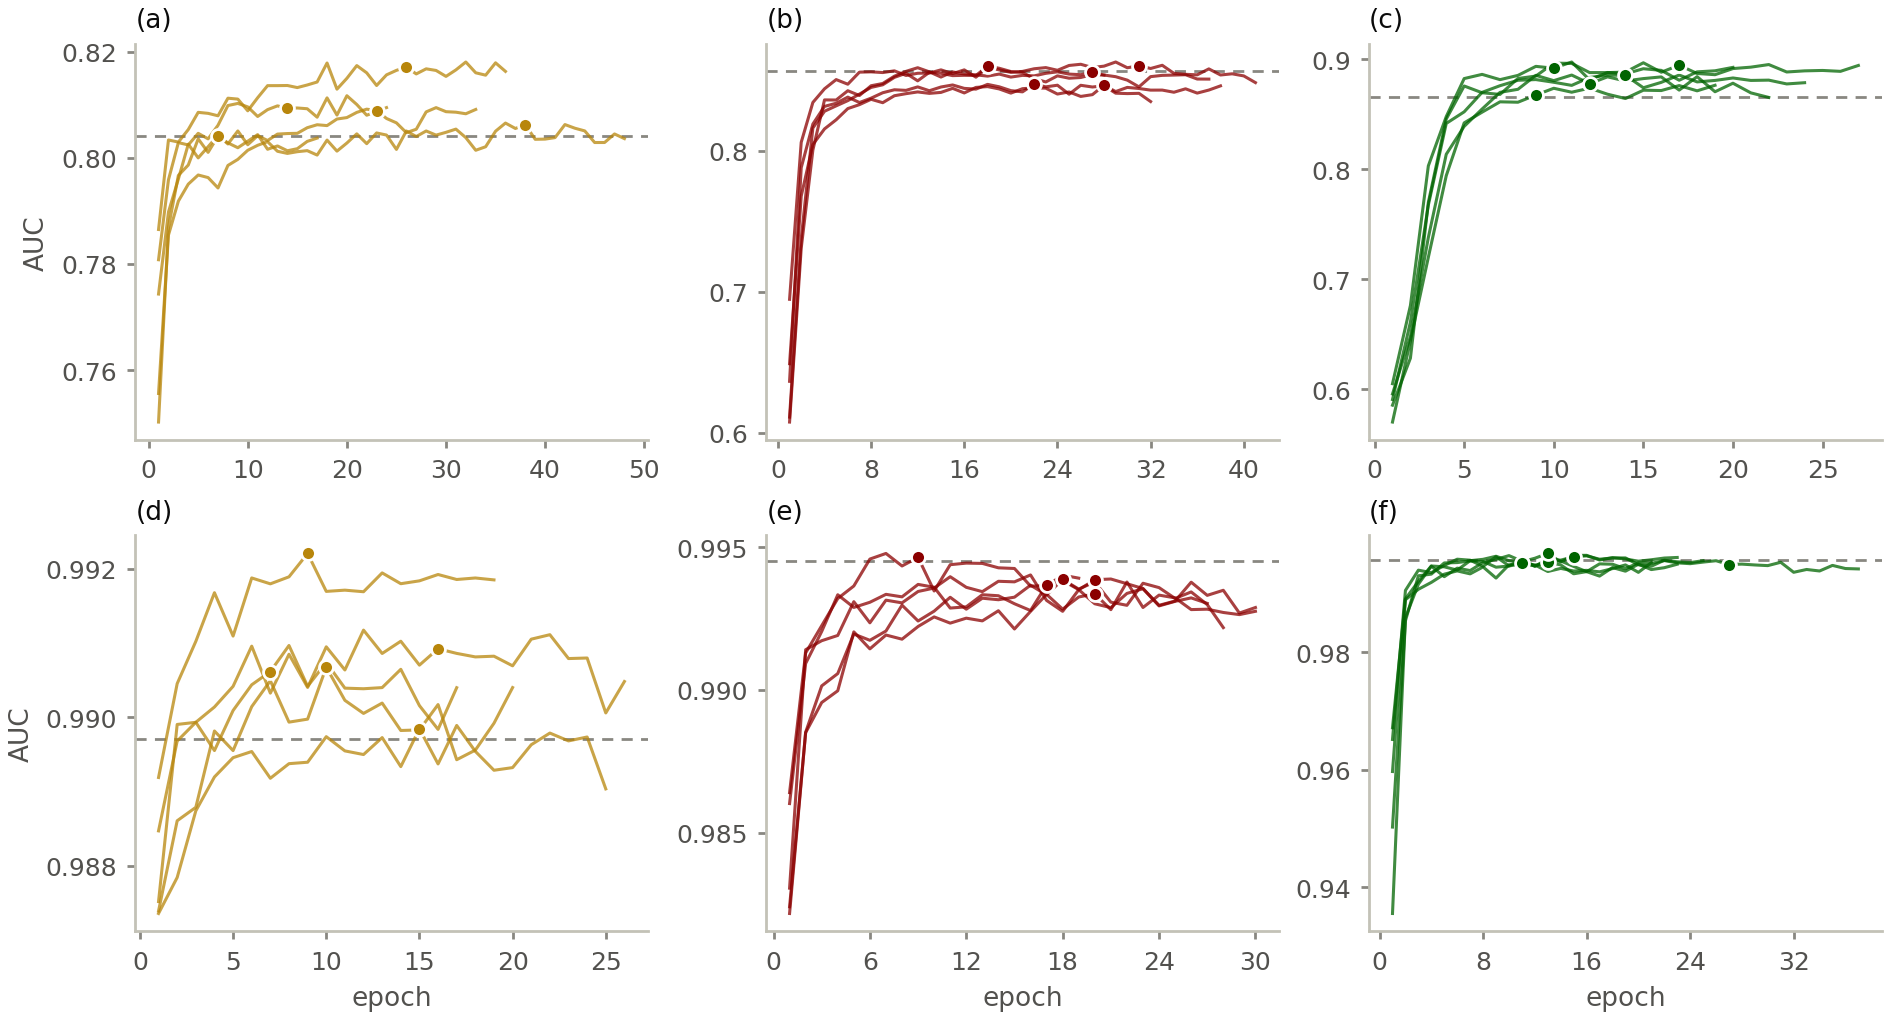

In [8]:
rows = ("thinned", "raw")
fig, axes = plt.subplots(2, 3, figsize=(3.15 * 3, 2.55 * 2), dpi=200, layout="constrained", facecolor=BG)
for j, L in enumerate(SIZES):
    history = m.training_history(L)
    for i, variant in enumerate(rows):
        ax = axes[i, j]
        ax.set_facecolor(BG)
        ax.set_axisbelow(True)
        ax.spines[["top", "right"]].set_visible(False)
        ax.spines[["bottom", "left"]].set(color=AXIS, linewidth=1.0)
        ax.tick_params(color=GRAY, labelcolor=LABEL, labelsize=9, length=3, width=1.0)

        for h in history[variant].values():
            loss, auc = h[:, 1], h[:, 2]
            saved = int(np.argmin(loss))
            ax.plot(np.arange(1, len(h) + 1), auc, color=COLORS[L], linewidth=1.1, alpha=0.75, zorder=3)
            ax.plot(saved + 1, auc[saved], linestyle="", marker="o", color=COLORS[L], markersize=5, markeredgecolor=BG, markeredgewidth=1.0, zorder=5)
        ax.axhline(network[L][variant]["auc"], color=GRAY, linewidth=1.0, linestyle=(0, (4, 3)), zorder=2)

        ax.xaxis.set_major_locator(MaxNLocator(integer=True, nbins=6))
        ax.yaxis.set_major_locator(MaxNLocator(nbins=5, steps=[1, 2, 5, 10]))
        decimals = max(0, int(np.ceil(-np.log10(np.diff(ax.get_yticks()).min()) - 1e-9)))
        ax.yaxis.set_major_formatter(f"{{x:.{decimals}f}}")
        ax.set_title(f"({'abcdef'[3 * i + j]})", fontsize=9.5, color=TEXT, loc="left", pad=6)
        if i == 1:
            ax.set_xlabel("epoch", fontsize=9.5, color=LABEL)
        if j == 0:
            ax.set_ylabel("AUC", fontsize=9.5, color=LABEL)

fig.savefig("../data_repository/figures/fig_learning_curves.png")
fig.savefig("../data_repository/figures/fig_learning_curves.pdf")
plt.close(fig)
display(Image("../data_repository/figures/fig_learning_curves.png"))